In [2]:
import numpy as np
import uproot
import matplotlib.pyplot as plt

[-1.   -0.96 -0.92 -0.88 -0.84 -0.8  -0.76 -0.72 -0.68 -0.64 -0.6  -0.56
 -0.52 -0.48 -0.44 -0.4  -0.36 -0.32 -0.28 -0.24 -0.2  -0.16 -0.12 -0.08
 -0.04  0.    0.04  0.08  0.12  0.16  0.2   0.24  0.28  0.32  0.36  0.4
  0.44  0.48  0.52  0.56  0.6   0.64  0.68  0.72  0.76  0.8   0.84  0.88
  0.92  0.96  1.  ]


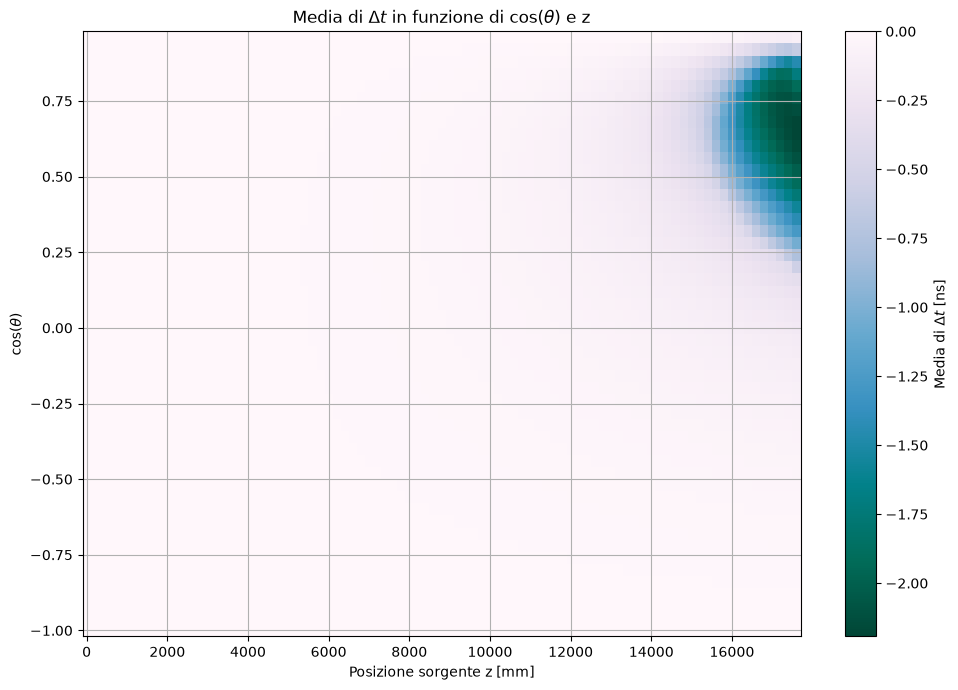

In [3]:
with uproot.open("output3.root") as file:
    tree = file["tof_cal"]
    data = tree.arrays(library= "np")

# Ora io devo prendere la media di delta tra i pmt con un certo cos_theta
a= np.linspace(-1, 1 ,51)

z_source = np.loadtxt("pos_z2.txt")
print(a)

delta_mean= np.full(shape=(len(a)-1, len(z_source)), fill_value=np.nan)


for j,z  in enumerate(z_source):
    for i in range(len(a)-1):
        mask = (data["cos_theta"] >= a[i]) & (data["cos_theta"] < a[i+1]) & (data["posZ"]==z)
        delta_mean[i, j] = np.mean(data["delta_ns"][mask])

fig, ax = plt.subplots(figsize=(10, 7))

plot = ax.pcolormesh(
    z_source,
    a[:-1],
    delta_mean,
    shading="auto",
    cmap="PuBuGn_r"
)

cbar = fig.colorbar(plot, ax=ax)
cbar.set_label(r"Media di $\Delta t$ [ns]")

ax.set_xlabel("Posizione sorgente z [mm]")
ax.set_ylabel(r"$\cos(\theta)$")
ax.set_title(r"Media di $\Delta t$ in funzione di $\cos(\theta)$ e z")
ax.grid()

plt.tight_layout()
plt.show()


In [27]:
b = np.arange(0, 17700, 200)
np.savetxt("pos_z2.txt", b)

[-1.   -0.96 -0.92 -0.88 -0.84 -0.8  -0.76 -0.72 -0.68 -0.64 -0.6  -0.56
 -0.52 -0.48 -0.44 -0.4  -0.36 -0.32 -0.28 -0.24 -0.2  -0.16 -0.12 -0.08
 -0.04  0.    0.04  0.08  0.12  0.16  0.2   0.24  0.28  0.32  0.36  0.4
  0.44  0.48  0.52  0.56  0.6   0.64  0.68  0.72  0.76  0.8   0.84  0.88
  0.92  0.96  1.  ]


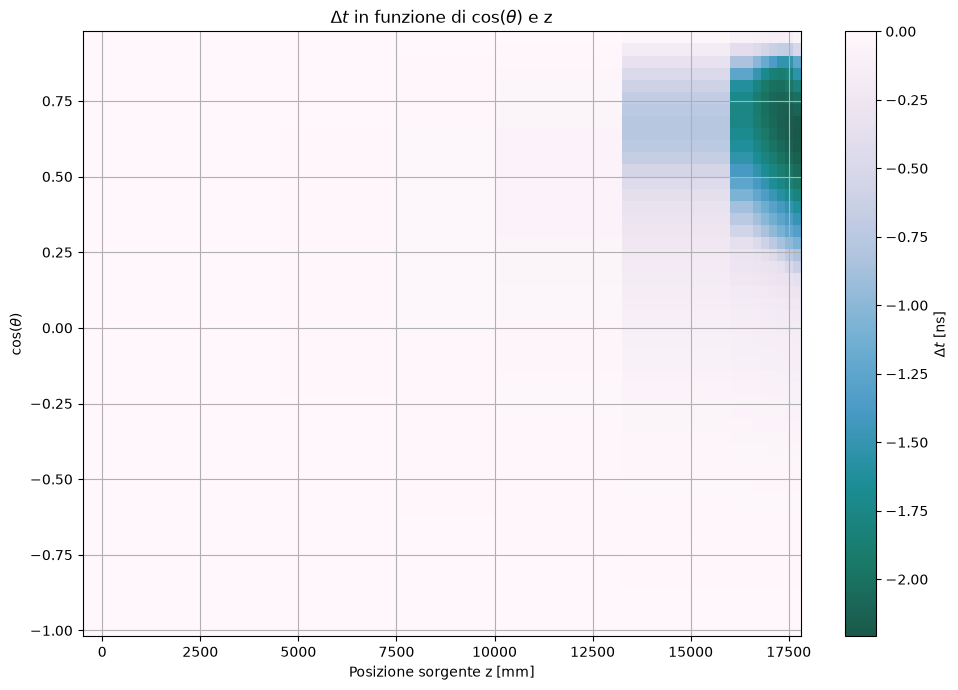

In [5]:
with uproot.open("output2.root") as file:
    tree = file["tof_cal"]
    data = tree.arrays(library= "np")

# Ora io devo prendere la media di delta tra i pmt con un certo cos_theta
a= np.linspace(-1, 1 ,51)

z_source = np.loadtxt("pos_z.txt")
print(a)

delta_mean= np.full(shape=(len(a)-1, len(z_source)), fill_value=np.nan)


for j,z  in enumerate(z_source):
    for i in range(len(a)-1):
        mask = (data["cos_theta"] >= a[i]) & (data["cos_theta"] < a[i+1]) & (data["posZ"]==z)
        delta_mean[i, j] = np.mean(data["delta_ns"][mask])

fig, ax = plt.subplots(figsize=(10, 7))

plot = ax.pcolormesh(
    z_source,
    a[:-1],
    delta_mean,
    shading="auto",
    cmap="PuBuGn_r",
    alpha = 0.9
)

cbar = fig.colorbar(plot, ax=ax)
cbar.set_label(r"$\Delta t$ [ns]")

ax.set_xlabel("Posizione sorgente z [mm]")
ax.set_ylabel(r"$\cos(\theta)$")
ax.set_title(r"$\Delta t$ in funzione di $\cos(\theta)$ e z")
ax.grid()   
plt.tight_layout()
plt.show()
